# 2. The engine's options

`carbon_ocr.Engine` takes the engine's options as keyword arguments. This notebook goes through them on the sample pages, each where it makes a difference, and measures what it changes: the text, the lines and the time. The command line takes the same options (notebook 6).

| option | default | what it sets |
|---|---|---|
| `workers`, `pin` | `0` (one per physical core), `True` | how many workers read pages, and whether each is pinned to its core |
| `precision` | `"auto"` | which of the set's files the models run: `"auto"`, `"fp32"`, `"fp16"` or `"int8"` |
| `rec` | `"rec-latin"` | the recognizer: `<set>/<rec>.onnx` and `<rec>.vocab.json` |
| `order_model` | `None` | another order model in place of the set's (a `.bin` runs natively, an ONNX file on ONNX Runtime) |
| `gate` | `True` | drop lines that are not text: rules and marks, slivers, unsure pieces read out of pictures |
| `block_order` | `"geometry"` | the order of the order model's blocks: by their geometry, columns first, or `"model"` as the model gave them |
| `single_pixel` | `0.8` | how sure a band one map pixel high must be to count as a line |
| `justified` | `False` | a justified line whose word gaps are all wide is kept whole, not split into cells |
| `table_spans` | `True` | tables laid out with their spanning cells (`colspan`, `rowspan`) |
| `flip_needs_dark` | `True` | the crop rule flips light text on a dark ground only where the crop is also mostly dark |
| `second_pass_share`, `second_pass_target` | `0`, `0` | when, and at what scale, a page of tiny text is detected a second time |
| `det_area`, `det_pitch` | `0`, `0` | pages of an unusual shape (a receipt) or of very large type (a slide) detected at a scale of their own |
| `char_confidence` | `True` | a line's confidence over its characters, its spaces left out |
| `spaces_from_ink` | `False` | drop a space the recognizer is unsure of where the line's ink shows no gap |
| `bucket_ratio` | `1.3` | how much wider each width bucket of the recognizer's batches is than the last |
| `fused_rec_head`, `det_stem` | `False`, `False` | two kernels of the engine's own for the FP32 files: the recognizer's last layer with CTC's argmax, and the detector's first layers |
| `share_sessions` | `True` | one ONNX Runtime session a model for every worker, or one a worker |
| `word_boxes_at_ink` | `False` | each word's box at its ink. Words come in the command line's JSON (notebook 6), not in this module's dicts |

The C++ API has more (`EngineOptions` in `carbon/engine.h`): the detector's scale, the deskew's limits, the rules for splitting lines and finding tables. The [engine guide](https://github.com/karanvora2599/Carbon-OCR/blob/main/docs/ENGINE.md) describes every one.

In [1]:
import time

import matplotlib.pyplot as plt
from IPython.display import HTML, display

import carbon_ocr
import helpers
import sample_pages

plt.rcParams["figure.dpi"] = 90
SET = helpers.model_set()
pages = sample_pages.make_all("data")
images = {name: carbon_ocr.load_image(path) for name, path in pages.items()}


def compare(name, variants, repeat=3, image=None):
    """A sample page read by one engine per variant, {label: options}. The reads take turns, so a machine
    that slows as it warms slows every variant alike. For each label, the read of median time:
    (page, ms, CER against the page's truth)."""
    image = images[name] if image is None else image
    engines = {label: carbon_ocr.Engine(SET, **options) for label, options in variants.items()}
    for engine in engines.values():
        engine.ocr([image])  # a first read warms the workers' caches
    runs = {label: [] for label in engines}
    for _ in range(repeat):
        for label, engine in engines.items():
            t = time.perf_counter()
            page = engine.ocr([image])[0]
            runs[label].append(((time.perf_counter() - t) * 1000, page))
    truth = sample_pages.truth_text(pages[name])
    out = {}
    for label, r in runs.items():
        ms, page = sorted(r, key=lambda x: x[0])[len(r) // 2]
        wrong, n, _, _ = carbon_ocr.text_errors([truth], [page["text"]])[0]
        out[label] = (page, ms, wrong / n)
    return out


def report(results, name=None):
    """A line of results for each variant. With the page's name, also the CER line by line: each line of the
    truth against the line the engine found over it, which the reading order does not change."""
    for label, (page, ms, cer) in results.items():
        by_line = ""
        if name:
            by_line = f" ({helpers.line_cer(sample_pages.truth(pages[name])['lines'], page['lines']):.2%} line by line)"
        print(f"{label:28} {len(page['lines']):4} lines  CER {cer:6.2%}{by_line}  {ms:6.1f} ms  "
              f"(detect {page['ms']['detect']:5.1f}, second pass {page['ms']['second_pass']:5.1f}, "
              f"recognize {page['ms']['recognize']:5.1f})")

The times below are medians of a few reads on the laptop these notebooks were run on: an Intel Core i7-13620H (6 performance and 4 efficiency cores), with nothing else running. They vary from run to run, at times by a third, so read small differences as noise.

## Workers: `workers`, `pin`

`workers=0`, the default, starts one worker per physical core, not per hardware thread: a core's two threads share its arithmetic units. Each worker is pinned to its core and runs every model on one thread, so the pool is the only parallelism and the OS never juggles more threads than there are cores. A page's lines become tasks of their own, so even a few pages spread over every core. `pin=False` leaves the workers to the OS, which suits a machine that other programs share.

In [2]:
batch = [images[n] for n in ["letter", "columns", "table", "banner", "scan", "skewed"]] * 3
for workers in [1, 2, 4, 0]:
    engine = carbon_ocr.Engine(SET, workers=workers)
    engine.ocr(batch[:4])
    t = time.perf_counter()
    engine.ocr(batch)
    print(f"workers={workers}: {engine.workers:2} workers, {len(batch) / (time.perf_counter() - t):5.1f} pages a second")
    del engine

workers=1:  1 workers,   7.8 pages a second


workers=2:  2 workers,  14.7 pages a second


workers=4:  4 workers,  22.0 pages a second


workers=0: 10 workers,  27.6 pages a second


On a hybrid CPU the efficiency cores join last: a worker on an E-core takes only the lines of pages already started, never a new page.

## Model files: `precision`

| `precision` | on the CPU |
|---|---|
| `"auto"` | the native int8 kernels where the set has `<model>.int8.onnx`, else the FP32 file on ONNX Runtime |
| `"fp32"` | `<model>.onnx`, on ONNX Runtime |
| `"fp16"` | `<model>.fp16.onnx`, on the engine's own kernels |
| `"int8"` | `<model>.int8.onnx`, on the engine's own kernels |

A precision the set has no file for is an error. `fullerene-3M` ships FP32 and FP16 files, so `"auto"` runs FP32 here.

In [3]:
try:
    carbon_ocr.Engine(SET, precision="int8")
except Exception as e:  # the message names the missing file, then why
    print("int8:", str(e).rsplit(": ", 1)[-1])
results = compare("letter", {f"precision={p!r}": dict(precision=p) for p in ["auto", "fp32", "fp16"]}, repeat=5)
report(results)
print("FP16's text the same as FP32's:", results["precision='fp16'"][0]["text"] == results["precision='fp32'"][0]["text"])

int8: the set has no int8 file for orient


precision='auto'               21 lines  CER  0.00%    46.1 ms  (detect  16.9, second pass   0.0, recognize  19.9)
precision='fp32'               21 lines  CER  0.00%    44.9 ms  (detect  10.7, second pass   0.0, recognize  23.3)
precision='fp16'               21 lines  CER  0.00%    97.9 ms  (detect  59.6, second pass   0.0, recognize  24.2)
FP16's text the same as FP32's: True


On a CPU with FP16 arithmetic (AVX-512 FP16, Armv8.2 FP16) the FP16 files are summed in FP16. Without it, as on this AVX2 laptop, each layer's weights are widened to FP32 at every run and summed in FP32. That halves the weights' memory, but here it runs slower than ONNX Runtime's FP32. Where a set has int8 files, `"auto"` picks them: on one core the native int8 recognizer runs about 2.5 times as fast as ONNX Runtime in FP32.

## Lines that are not text: `gate`

What the recognizer reads out of a photograph, a rule, a speck or a page's edge is dropped before the lines are ordered. That covers lines that read nothing or only rules and marks (`_ - — . | = ~ • /`), slivers (a box taller than 1.6 times its width that reads at most 2 characters), unsure pieces on the detector's picture map, and lone unsure marks. `gate=False` keeps every line. `columns.png` has rules under its running header and over its footnote.

gate=True                      44 lines  CER 49.16% (5.93% line by line)    59.3 ms  (detect  18.8, second pass   0.0, recognize  28.1)
gate=False                     46 lines  CER 50.68% (5.93% line by line)    55.2 ms  (detect  14.7, second pass   0.0, recognize  27.5)
  dropped by the gate: '__________________'     box (942, 1998, 1456, 2049)  confidence 0.86
  dropped by the gate: '___'                    box (1502, 2006, 1524, 2048)  confidence 0.91


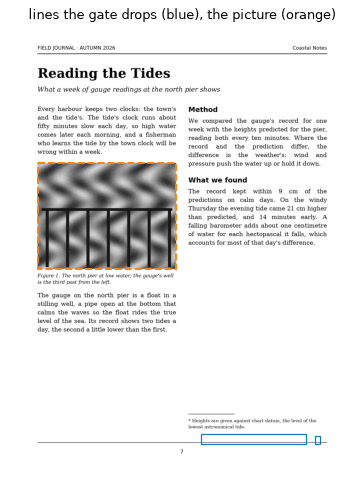

In [4]:
results = compare("columns", {"gate=True": {}, "gate=False": dict(gate=False)}, repeat=1)
report(results, "columns")
kept, every = results["gate=True"][0], results["gate=False"][0]
texts_kept = [line["text"] for line in kept["lines"]]
extra = [line for line in every["lines"] if line["text"] not in texts_kept]
for line in extra:
    print(f"  dropped by the gate: {line['text']!r:24} box {tuple(round(v) for v in line['box'])}  "
          f"confidence {line['confidence']:.2f}")
helpers.show(images["columns"], extra, kept["pictures"], title="lines the gate drops (blue), the picture (orange)", width=5);

The page's CER in reading order is high for a reason the next section shows. Line by line it is far lower, and most of what is left is one justified line split into its words, which `justified=True` mends (further down).

## Reading order and blocks: `block_order`

The order model puts a page's lines in reading order and groups them into labelled blocks. Where it is unsure of its order (the mean probability of its links under 0.5), the engine takes the XY-cut's order instead, which cuts the page at its widest gaps again and again; a page's `order` says which it got. The blocks are then put in an order of their own by their geometry, a page's columns first (`block_order="geometry"`), or kept in the model's order (`"model"`).

In [5]:
results = compare("columns", {f"block_order={b!r}": dict(block_order=b, justified=True) for b in ["geometry", "model"]},
                  repeat=1)
report(results, "columns")
for label, (page, _, _) in results.items():
    print(f"\n{label}: the order within blocks from the {page['order']}; the blocks in order:")
    for b in page["blocks"]:
        print(f"   {b['label']:15} {page['lines'][b['lines'][0]]['text'][:56]}")

block_order='geometry'         34 lines  CER 48.40% (0.16% line by line)    57.3 ms  (detect  18.3, second pass   0.0, recognize  26.9)
block_order='model'            34 lines  CER  2.36% (0.16% line by line)    57.4 ms  (detect  14.8, second pass   0.0, recognize  28.4)

block_order='geometry': the order within blocks from the model; the blocks in order:
   Page-Header     FIELD JOURNAL - AUTUMN 2026
   Page-Header     Coastal Notes
   Section-Header  Reading the Tides
   Text            What a week of gauge readings at the north pier shows
   Section-Header  Method
   Text            We compared the gauge's record for one
   Section-Header  What we found
   Text            The record kept within 9 cm of the
   Caption         Figure 1. The north pier at low water; the gauge's well
   Text            The gauge on the north pier is a float in a
   Caption         * Heights are given against chart datum, the level of th

block_order='model': the order within blocks from the model; the b

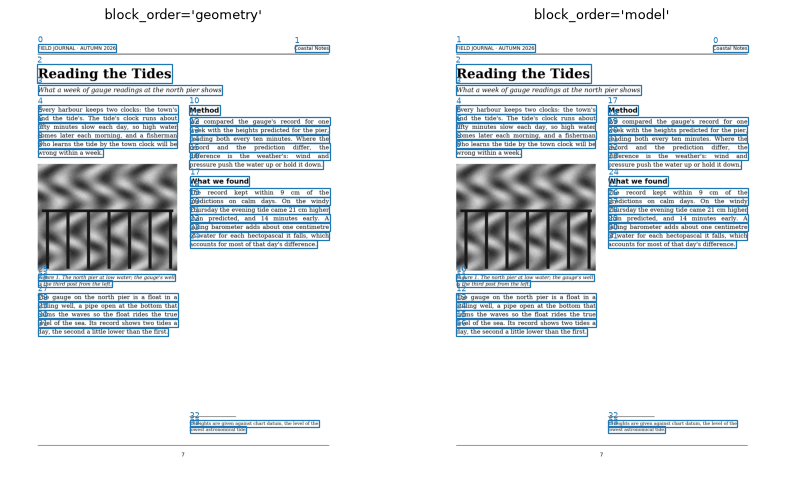

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 7.4))
for ax, (label, (page, _, _)) in zip(axes, results.items()):
    helpers.show(images["columns"], page["lines"], ax=ax, title=label, label=True)

The labels are right in both: the two `Page-Header` blocks, the title, the `Text` blocks, the `Section-Header`s and the figure's `Caption`. The orders differ.

- **The model's order** reads down column 1, past the figure and its caption, then column 2, as a reader does. It puts the right-hand running header before the left one.
- **The geometry's order**, the default, reads column 2 before the lower half of column 1. It orders the blocks by cutting the page at its widest gaps. Here the picture leaves a gap across the whole page just below the end of column 2's text, so the page is cut there first.

The default comes from measuring both on many real pages, where ordering by geometry did better. On a page like this one, `block_order="model"` reads it right. Notebook 4 runs the XY-cut, the same kind of cut, on the lines alone.

## One-pixel lines: `single_pixel`

The line decoder treats a core band under 2 map pixels as noise, unless its one pixel is at least `single_pixel` sure (0.8). A line under about 5 px high at the detector's scale has only one such pixel. The page number at the foot of `columns.png`, a lone "7", is one map pixel at 0.57.

In [7]:
results = compare("columns", {
    "single_pixel=0.8": dict(block_order="model", justified=True),
    "single_pixel=0.5": dict(block_order="model", justified=True, single_pixel=0.5),
    "single_pixel=0.5, gate=False": dict(block_order="model", justified=True, single_pixel=0.5, gate=False),
}, repeat=1)
report(results, "columns")
for label, (page, _, _) in results.items():
    foot = [line["text"] for line in page["lines"] if line["box"][1] > 1990]  # the foot of the page
    print(f"{label:28} the lines at the foot of the page: {foot}")

single_pixel=0.8               34 lines  CER  2.36% (0.16% line by line)    59.6 ms  (detect  16.7, second pass   0.0, recognize  30.5)
single_pixel=0.5               34 lines  CER  2.36% (0.16% line by line)    64.9 ms  (detect  26.7, second pass   0.0, recognize  26.5)
single_pixel=0.5, gate=False   37 lines  CER 17.02% (0.08% line by line)    56.9 ms  (detect  16.2, second pass   0.0, recognize  26.7)
single_pixel=0.8             the lines at the foot of the page: []
single_pixel=0.5             the lines at the foot of the page: []
single_pixel=0.5, gate=False the lines at the foot of the page: ['__________________', '___', '7']


At 0.5 the detector keeps the "7", but the gate then drops it as a sliver: its box is 14 px wide and 35 px tall, and it reads one character. With the gate off as well, the page number comes back, along with the two rules the gate drops. Those extra lines also change the order the model gives the page, so its CER in reading order jumps while its CER line by line falls. A lower `single_pixel` finds lone small marks, and also more specks taken for lines.

## Justified text: `justified`

After recognition the engine splits a line at a wide gap, so a line the detector ran across a column gutter or a table row's cells becomes one line per cell. A justified line's stretched spaces can look like such gaps. With `justified=True`, a line none of whose gaps is narrow takes its smallest gap as its word space, and splits only at a gap of 1.5 line heights.

In [8]:
report(compare("columns", {"columns, justified=False": {}, "columns, justified=True": dict(justified=True)},
               repeat=1), "columns")
report(compare("newspaper", {"newspaper, justified=False": {}, "newspaper, justified=True": dict(justified=True)},
               repeat=1), "newspaper")
plain = carbon_ocr.Engine(SET).ocr([images["columns"]])[0]
print("\ncolumns.png, justified=False, around the split line:")
print(" | ".join(line["text"] for line in plain["lines"][13:24]))

columns, justified=False       44 lines  CER 49.16% (5.93% line by line)    77.3 ms  (detect  18.4, second pass   0.0, recognize  45.6)
columns, justified=True        34 lines  CER 48.40% (0.16% line by line)    57.2 ms  (detect  18.6, second pass   0.0, recognize  29.1)


newspaper, justified=False    945 lines  CER  0.51% (2.98% line by line)   801.7 ms  (detect  10.8, second pass  93.8, recognize 600.7)


newspaper, justified=True     810 lines  CER  0.03% (0.03% line by line)   832.0 ms  (detect  12.1, second pass  95.8, recognize 647.7)

columns.png, justified=False, around the split line:
reading both every ten minutes. Where the | record | and | the | prediction | differ, | the | difference | is | the | weather's:


## Tables: `table_spans`

The order model finds a table's cells and gives each its row and column. With `table_spans=True`, a cell that lies over more than half of two of the model's columns, such as a header over them, spans them (`colspan`). The HTML and markdown writers give the spans, and so does the command line's JSON. On `table.png` the header "Passengers (thousands)" is centred over four columns, but it covers more than half of only the middle two, so it spans those two.

In [9]:
for spans in [True, False]:
    page = carbon_ocr.Engine(SET, table_spans=spans).ocr([images["table"]], html=True)[0]
    table = next(b for b in page["blocks"] if b["label"] == "Table")
    print(f"table_spans={spans}: {len(table['cells'])} cells; row 0:",
          [(row, col, page["lines"][lines[0]]["text"]) for row, col, lines in table["cells"] if row == 0])
    start = page["html"].index("<table")
    display(HTML(page["html"][start:page["html"].index("</table>") + 8]))

table_spans=True: 43 cells; row 0: [(0, 0, 'Route'), (0, 2, 'Passengers (thousands)'), (0, 5, 'Year')]


table_spans=False: 43 cells; row 0: [(0, 0, 'Route'), (0, 2, 'Passengers (thousands)'), (0, 5, 'Year')]


Route,,Passengers (thousands),,,Year
,Q1,Q2,Q3,Q4,
Harbour to Northgate,41.2,44.8,58.3,39.6,183.9
Harbour to Saltmarsh,18.5,20.1,27.4,17.9,83.9
Northgate to Saltmarsh,9.7,10.4,15.2,8.8,44.1
Island shuttle,6.1,7.9,12.6,5.4,32.0
Evening crossing,3.3,4.0,6.8,2.9,17.0
All routes,78.8,87.2,120.3,74.6,360.9


## Light text on dark grounds: `flip_needs_dark`

The recognizer reads dark ink on light paper. The crop rule flips a line's crop (255 − v) when more of its pixels are much lighter than its ground than much darker. With `flip_needs_dark=True`, the default, over half of the crop's pixels must also be dark. That matters where both of a crop's padding rows land on a table's rules: the ground then reads dark, though the crop is dark text on paper. `banner.png` has a banner, a grey box and a table header row in light text, and a rule under each table row.

In [10]:
results = compare("banner", {f"flip_needs_dark={f}": dict(flip_needs_dark=f) for f in [True, False]}, repeat=1)
report(results)
print()
print(results["flip_needs_dark=True"][0]["text"])

flip_needs_dark=True           14 lines  CER  0.25%    51.0 ms  (detect  18.8, second pass   0.0, recognize  20.2)
flip_needs_dark=False          14 lines  CER  0.25%    66.0 ms  (detect  18.4, second pass   0.0, recognize  37.6)

Harbour Open Day
Saturday 9 May · 10:00 to 16:00 · Free entry
The harbour office opens its doors for one day a year. Visitors can climb the pier's tide
gauge, take a short trip on the survey boat and see the charts the office keeps.
 Time
Event
10:00
The harbour master opens the day
11:30
Survey boat trips leave the slip
13:00
Talk: how the channel is charted
15:00
Last boat trip of the day



Both read this page alike: its light lines are flipped and read, and its rules never darken a crop's ground. The one error is a stray space before "Time" in the table's header.

## Tiny text: the second detection pass

The detector sees the page at a long side of 1024 px and gives its maps at half that scale. A line under 9 px high at that scale has a core band of one or two map rows, so the detector misses some such lines and places the rest coarsely. When a page's median line is under 9 px, the engine detects the page a second time at twice the scale and merges the two passes line by line. `newspaper.png`, six columns of 24 px type on a 3400 × 4800 page, is such a page: at the detector's scale its lines are under 8 px high.

newspaper                     810 lines  CER  0.03% (0.03% line by line)   764.5 ms  (detect  10.0, second pass  99.1, recognize 591.3)
second pass: True (99 ms of 764)


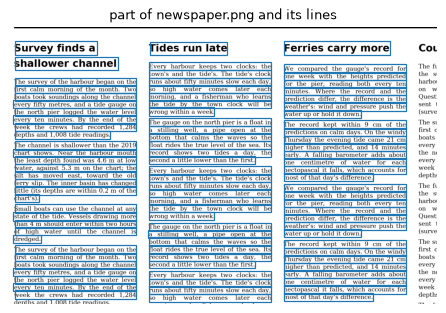

In [11]:
page, ms, cer = compare("newspaper", {"newspaper": dict(justified=True)}, repeat=1)["newspaper"]
report({"newspaper": (page, ms, cer)}, "newspaper")
print("second pass:", page["second_pass"], f"({page['ms']['second_pass']:.0f} ms of {page['ms']['total']:.0f})")
fig, ax = plt.subplots(figsize=(9, 4))
inside = [dict(box=(l["box"][0] - 100, l["box"][1] - 300, l["box"][2] - 100, l["box"][3] - 300))
          for l in page["lines"] if l["box"][1] > 300 and l["box"][3] < 1400 and l["box"][2] < 1800]
helpers.show(images["newspaper"][300:1400, 100:1800], inside, ax=ax, title="part of newspaper.png and its lines");

`second_pass_target` scales the second pass so the tiny lines' median height comes to that many pixels, instead of doubling the scale. `second_pass_share` also takes the second pass where at least that share of a page's lines (and 8 of them) are tiny, though the median is not. `mixed.png` is a form at 300 dpi: ordinary print, then its conditions in two columns of 4-point type.

In [12]:
report(compare("newspaper", {"newspaper, target 18 px": dict(justified=True, second_pass_target=18)}, repeat=1),
       "newspaper")
results = compare("mixed", {f"mixed, second_pass_share={s}": dict(second_pass_share=s) for s in [0, 0.2]}, repeat=1)
report(results)
for label, (page, _, _) in results.items():
    print(f"\n{label}: second pass {page['second_pass']}")
    for line in page["lines"][12:24]:
        print(f"   {line['confidence']:.2f}  {line['text'][:80]}")

newspaper, target 18 px       807 lines  CER  0.00% (0.00% line by line)   890.7 ms  (detect  18.0, second pass 133.6, recognize 659.4)


mixed, second_pass_share=0     32 lines  CER  1.36%    62.9 ms  (detect  18.5, second pass   0.0, recognize  32.7)
mixed, second_pass_share=0.2   32 lines  CER  6.97%    78.3 ms  (detect  16.5, second pass  15.2, recognize  33.4)

mixed, second_pass_share=0: second pass False
   0.90  L. These terms apply to veny ticket sold by the harbour ofice for the ferry rout
   1.00  bought at the office, on board or through an agent.
   0.94  2. A ticket is vlid on y for the oute the date and the class oftravel printed n 
   1.00  month from the date of the outward journey.
   0.87  3. The office may chonge
   0.96  timetable,a vessel or a route without natice where the weather, the tide or the 
   1.00  vessel makes it necessary for safety.
   0.90  4 A poosenger whose crosin is cancelled may travel on the next rosing or have th
   1.00  other costs are refunded.
   0.97  $. Children under five travel free with an adult. Children from five to fifteen 
   1.00  travels at the child's fare.
   1.

On the newspaper, a target of 18 px reads the last few errors right, for about 10% more time.

On the form, the second pass costs accuracy. Neither pass reads the first lines of the left column's conditions well: the first pass gives each of them a box that runs into the line below, and the recognizer misreads it ("veny ticket", "vlid on y"). At the first pass's scale those boxes are not tiny, so the merge keeps them. The second pass's lines also change the order: condition 3 moves after condition 6. Where two passes disagree, a second pass can make a page worse. That is why `second_pass_share` is off by default. Measure it on your own pages before you turn it on.

## Pages of an unusual shape or size: `det_area`, `det_pitch`

The detector fits a page's long side to 1024 px, so a receipt, a long narrow strip, shrinks to very few pixels. With `det_area` set, a page whose fit leaves it under half that many pixels is detected at that many instead, at most at its own size.

In [13]:
results = compare("receipt", {f"receipt, det_area={a}": dict(det_area=a) for a in [0, 1024 * 1024]}, repeat=5)
report(results)
print()
print(" | ".join(line["text"] for line in results["receipt, det_area=0"][0]["lines"][-6:]))
print(" | ".join(line["text"] for line in results["receipt, det_area=1048576"][0]["lines"][-6:]))

receipt, det_area=0            57 lines  CER  0.43%    23.8 ms  (detect   3.4, second pass   0.0, recognize  10.9)
receipt, det_area=1048576      55 lines  CER  0.00%    47.1 ms  (detect  24.1, second pass   0.0, recognize   9.7)

2.10 | TOTAL | 89.60 | Thank you, | come | again
3.20 | Flapjack | 2.10 | TOTAL | 89.60 | Thank you, come again


At the default scale the receipt's last line is split into three pieces, and a few characters are misread. Detected at a megapixel, it reads without an error, for about 20 ms more of detection.

A slide is the opposite case: a few lines of very large type, many more pixels than its text needs. With `det_pitch` set, a page whose line pitch at the detector's scale is over that many pixels is detected at the scale that brings its pitch to that, though at no less than half the detector's side.

In [14]:
untitled = images["slide"][250:].copy()  # the slide without its title
for label, image in [("slide", None), ("slide without its title", untitled)]:
    results = compare("slide", {"det_pitch=0": {}, "det_pitch=24": dict(det_pitch=24)}, repeat=9, image=image)
    (a, _, _), (b, _, _) = results.values()
    print(f"{label}: detect {a['ms']['detect']:.1f} ms, with det_pitch=24 {b['ms']['detect']:.1f} ms")
    for x, y in zip(a["lines"], b["lines"]):
        if x["text"] != y["text"]:
            print(f"   {x['text']!r} became {y['text']!r}")

slide: detect 10.5 ms, with det_pitch=24 8.5 ms


slide without its title: detect 9.2 ms, with det_pitch=24 2.6 ms
   '• Deep draught: two hours of high water' became '• Deep draught; two hours of high water'


On the slide as it is, `det_pitch` changes nothing. The engine estimates a page's pitch from the autocorrelation of its rows' ink at the detector's scale, and here the title's much larger letters hide the bullets' pitch. So it finds none, and the page is detected at the usual scale. Without the title it finds the pitch (59 px at the detector's scale) and detects the slide at half the scale, about three times quicker. One character changes, a colon read as a semicolon. `det_pitch` is off by default.

## Recognition: `char_confidence`, `spaces_from_ink`, `bucket_ratio`

A line's confidence is the mean probability of its characters, its spaces left out (`char_confidence=True`). With `False` it is the mean over every character the decoder kept, spaces included. Lines that read cleanly are near 1 either way. The difference shows on lines the recognizer is unsure of, such as the form's fine print.

In [15]:
results = compare("mixed", {"on": {}, "off": dict(char_confidence=False)}, repeat=1)
for a, b in list(zip(results["on"][0]["lines"], results["off"][0]["lines"]))[12:20]:
    print(f"over its characters {a['confidence']:.3f}   over every id {b['confidence']:.3f}   {a['text'][:50]}")

over its characters 0.900   over every id 0.898   L. These terms apply to veny ticket sold by the ha
over its characters 0.999   over every id 0.999   bought at the office, on board or through an agent
over its characters 0.941   over every id 0.937   2. A ticket is vlid on y for the oute the date and
over its characters 1.000   over every id 1.000   month from the date of the outward journey.
over its characters 0.872   over every id 0.872   3. The office may chonge
over its characters 0.956   over every id 0.956   timetable,a vessel or a route without natice where
over its characters 1.000   over every id 1.000   vessel makes it necessary for safety.
over its characters 0.900   over every id 0.907   4 A poosenger whose crosin is cancelled may travel


`spaces_from_ink=True` drops a space the recognizer is unsure of where the line's ink shows no gap. `bucket_ratio` sets the recognizer's width buckets: lines are batched by width, and each crop is padded to the smallest bucket that holds it. The buckets are 1.3 times apart by default, as the recognizers were trained. Closer buckets pad less; wider ones put more lines in a batch, and the recognizer then reads paddings it was not trained on.

In [16]:
results = compare("table", {"defaults": {}, "spaces_from_ink=True": dict(spaces_from_ink=True),
                            "bucket_ratio=1.15": dict(bucket_ratio=1.15), "bucket_ratio=1.6": dict(bucket_ratio=1.6)},
                  repeat=5)
report(results)
base = results["defaults"][0]["text"]
for label, (page, _, _) in results.items():
    print(f"{label:22} the same text as with the defaults: {page['text'] == base}")

defaults                       48 lines  CER  3.62%    35.3 ms  (detect  13.1, second pass   0.0, recognize  11.0)
spaces_from_ink=True           48 lines  CER  3.62%    36.5 ms  (detect  12.7, second pass   0.0, recognize  12.7)
bucket_ratio=1.15              48 lines  CER  3.62%    33.6 ms  (detect  10.7, second pass   0.0, recognize  11.1)
bucket_ratio=1.6               48 lines  CER  3.62%    39.9 ms  (detect  15.7, second pass   0.0, recognize  12.5)
defaults               the same text as with the defaults: True
spaces_from_ink=True   the same text as with the defaults: True
bucket_ratio=1.15      the same text as with the defaults: True
bucket_ratio=1.6       the same text as with the defaults: True


On this table the text is the same with each of them, and the times are within the noise.

## The engine's own kernels: `fused_rec_head`, `det_stem`

Both run part of an FP32 model on the engine's own kernels instead of ONNX Runtime:

- `fused_rec_head` computes the recognizer's last layer and CTC's argmax together on AVX2, so the logits are never written.
- `det_stem` runs the detector's first convolutions in row bands, so their large stride-2 tensor is never whole.

Both give the engine's sums, not ONNX Runtime's, so a text can differ in rare places. Both are off by default.

In [17]:
results = compare("letter", {"defaults": {}, "fused_rec_head=True": dict(fused_rec_head=True),
                             "det_stem=True": dict(det_stem=True)}, repeat=7)
report(results)
base = results["defaults"][0]["text"]
for label, (page, _, _) in results.items():
    print(f"{label:22} the same text as with the defaults: {page['text'] == base}")

defaults                       21 lines  CER  0.00%    46.1 ms  (detect  11.0, second pass   0.0, recognize  24.5)
fused_rec_head=True            21 lines  CER  0.00%    46.9 ms  (detect  12.4, second pass   0.0, recognize  23.8)
det_stem=True                  21 lines  CER  0.00%    49.1 ms  (detect  14.8, second pass   0.0, recognize  24.0)
defaults               the same text as with the defaults: True
fused_rec_head=True    the same text as with the defaults: True
det_stem=True          the same text as with the defaults: True


On this laptop neither is quicker than ONNX Runtime by more than the noise, and the text is the same.

## Sessions: `share_sessions`

With `share_sessions=True`, every worker runs one ONNX Runtime session of each model, so its weights are held once, in the caches the cores share. The text is the same either way. On a machine of several NUMA nodes, `False` keeps a copy in each worker's node.

In [18]:
engines = {share: carbon_ocr.Engine(SET, share_sessions=share) for share in [True, False]}
seconds = {share: [] for share in engines}
for engine in engines.values():
    engine.ocr(batch[:4])
for _ in range(3):  # in turns, as compare() does
    for share, engine in engines.items():
        t = time.perf_counter()
        engine.ocr(batch)
        seconds[share].append(time.perf_counter() - t)
for share, s in seconds.items():
    print(f"share_sessions={share}: {len(batch) / sorted(s)[1]:5.1f} pages a second")
del engines

share_sessions=True:  28.8 pages a second
share_sessions=False:  27.3 pages a second


Here the two are within the noise of each other. Measured on many more pages, shared sessions read 4 to 6% more pages a second on 6 and 10 workers.

## Summary

On these pages, these options changed what the engine read:

- `justified=True` mended justified columns: the newspaper's CER fell more than tenfold, and the two-column page's split line came back whole.
- `block_order="model"` read the two-column page in the right order, where the default did not.
- `single_pixel=0.5` with `gate=False` found a lone page number the defaults miss.
- `det_area` read the receipt better, for more detection time.
- `gate=False` let rules through as lines of underscores.
- `table_spans=False` dropped the header's span.
- `second_pass_share` read the form worse.
- `det_pitch` made a slide's detection three times quicker, but only once its title was cut off.

The others changed the time, not the text. Options are set per engine, so one program can keep engines with different options side by side: one for receipts and one for newspapers, say.